# H5 规划均值与每日回报：只读诊断

只读已合格的 `published_futu_affine_20260925_v1` 原生 Qlib 数据及父 Recorder `bd754e6362b241f194351a1e7aebff6f`。比较相同 H5 成熟日期上的均值与单位风险分数；不拟合预测模型、不优化仓位、不计算任何新策略路径、不改变 Phase 4。

年度 cutoff 固定为 2016—2023 年 1 月 1 日纽约时间，训练信号起点固定为 2011-01-03。2023 cutoff 对应 Phase 4 冻结的后续诊断均值。另按 2011—2026 年分别汇总 OPEN/CLOSE 同期单日 SOXL−3×SOXX 回报差，2026 仅到 9 月 25 日。

这些样本均值不构成超额收益、融资拖累或跟踪误差因果解释；SOXL 与 SOXX 也不是严格相同标的的 3× 恒等关系。

In [1]:
import os, sys, json, hashlib
from pathlib import Path
os.environ['MLFLOW_ALLOW_FILE_STORE']='true'
os.environ['MLFLOW_DISABLE_AGENT_HINT']='1'
ROOT=Path('/Users/rziiiii/dev/workspace-worktrees/conditional-variance-20261002')
ROOT=ROOT if ROOT.is_dir() else Path('/Users/rziiiii/dev/workspace')
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.data.conditional_variance import load_qualified_primary
from src.data.integrated_allocation import build_native_dataset, PRIMARY_FEATURES, PRIMARY_LABELS, PRIMARY_METADATA, frame_sha256
from src.data.convex_allocation import LABEL_COLUMNS as H5_LABELS
from src.workflow.benchmark_risk_excess import expanding_covariance, COVARIANCE_FIELDS
ASOF='2026-09-25'
source=load_qualified_primary(ROOT,provider_uri='data/qlib/published_futu_affine_20260925_v1',parent_summary='research/canonical_price_basis_20261002/summary.json',expected_recorder_id='bd754e6362b241f194351a1e7aebff6f',as_of=ASOF)
primary=source['primary_frame'];prices=source['execution_prices'].astype(float)
dataset=build_native_dataset(primary,feature_columns=PRIMARY_FEATURES,label_columns=(*PRIMARY_LABELS,*H5_LABELS),metadata_columns=(*PRIMARY_METADATA,'h5_exit_date','h5_available_at'),as_of=ASOF)
prepared=dataset.prepare('all',col_set=['feature','label','metadata']).copy()
prepared.columns=[col[-1] for col in prepared.columns]
prepared.index=pd.DatetimeIndex(prepared.index.get_level_values('datetime'))
assert prepared.index.equals(primary.index)
print({'native_rows':len(source['raw_ohlcv']),'signal_rows':len(primary),'native_hash':source['audit']['native_frame_sha256'],'model_fits':False,'portfolio_replays':False})

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


[88813:MainThread](2026-10-02 22:38:10,257) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[88813:MainThread](2026-10-02 22:38:10,258) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[88813:MainThread](2026-10-02 22:38:10,259) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': PosixPath('/Users/rziiiii/dev/workspace-worktrees/conditional-variance-20261002/data/qlib/published_futu_affine_20260925_v1')}


[88813:MainThread](2026-10-02 22:38:10,291) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


...

[88813:MainThread](2026-10-02 22:38:10,293) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': PosixPath('/Users/rziiiii/dev/workspace-worktrees/conditional-variance-20261002/data/qlib/published_futu_affine_20260925_v1')}


[88813:MainThread](2026-10-02 22:38:10,378) INFO - qlib.timer - [log.py:127] - Time cost: 0.000s | Loading data Done


[88813:MainThread](2026-10-02 22:38:10,378) INFO - qlib.timer - [log.py:127] - Time cost: 0.000s | fit & process data Done


[88813:MainThread](2026-10-02 22:38:10,379) INFO - qlib.timer - [log.py:127] - Time cost: 0.001s | Init data Done


{'native_rows': 8324, 'signal_rows': 3956, 'native_hash': 'b7a59f39feed5aed6e61fec2b4239092c474e453c91d4d133c73f9dcc571a03f', 'model_fits': False, 'portfolio_replays': False}


## 相同成熟日期与精确回报恒等式

每个信号 t 在 t+1 OPEN 入场：μ1 使用 `OPEN[t+2]/OPEN[t+1]−1`，μH5 使用 `OPEN[t+6]/OPEN[t+1]−1`。同一 I_y 上比较 μH5、5μ1、(1+μ1)^5−1。后两者是均值变换，均不等于已验证的动态交易策略收益。

同时核对 `H5 = ∏(1+r_k)−1`；把 `mean(H5)−5 mean(r_1)` 分解为五个实际日回报交叉乘积项及不同 offset 样本均值之差。原始模型每日标签存在 float32 除法舍入，以下明确保存其与原生价格 float64 重算值的最大差。

In [2]:
native_daily={};native_h5={};forward_sums={};identity_errors={};daily_label_rounding={}
for symbol in ('SOXL','SOXX'):
    opening=prices[('open',symbol)]
    daily=(opening.shift(-2)/opening.shift(-1)-1).reindex(primary.index)
    horizon=(opening.shift(-6)/opening.shift(-1)-1).reindex(primary.index)
    block=pd.concat([daily.shift(-offset) for offset in range(5)],axis=1)
    complete=block.notna().all(axis=1)
    reconstructed=(1+block).prod(axis=1)-1
    identity_errors[symbol]=float((reconstructed[complete]-horizon[complete]).abs().max())
    assert identity_errors[symbol] < 2e-14
    daily_label_rounding[symbol]=float((daily-primary[f'{symbol.lower()}_return']).abs().max())
    native_daily[symbol]=daily;native_h5[symbol]=horizon;forward_sums[symbol]=block.sum(axis=1).where(complete)
    assert np.nanmax(np.abs(horizon-primary[f'{symbol.lower()}_return_h5'])) == 0
native_daily=pd.DataFrame(native_daily);native_h5=pd.DataFrame(native_h5);forward_sums=pd.DataFrame(forward_sums)
covariance=expanding_covariance(prices)
annual=[];scores=[];mature_dates={}
for year in range(2016,2024):
    cutoff=pd.Timestamp(f'{year}-01-01',tz='America/New_York')
    mask=pd.to_datetime(prepared.feature_available_at,utc=True).lt(cutoff) & pd.to_datetime(prepared.h5_available_at,utc=True).lt(cutoff)
    dates=prepared.index[mask]
    assert len(dates)>=252 and dates.min()==pd.Timestamp('2011-01-03')
    mature_dates[str(year)]=dates.strftime('%Y-%m-%d').tolist()
    one=native_daily.loc[dates];five=native_h5.loc[dates];sums=forward_sums.loc[dates]
    assert np.isfinite(np.c_[one,five,sums]).all()
    means1=one.mean();means5=five.mean();summeans=sums.mean()
    same_std=one.std(ddof=1)
    last_known_open=covariance.index[covariance.index < cutoff.tz_localize(None)][-1]
    last_cov=covariance.loc[last_known_open]
    last_std=pd.Series({'SOXL':np.sqrt(last_cov.cov_soxl_soxl),'SOXX':np.sqrt(last_cov.cov_soxx_soxx)})
    for symbol in ('SOXL','SOXX'):
        mu1=float(means1[symbol]);mu5=float(means5[symbol]);linear=5*mu1;compound=(1+mu1)**5-1
        within=float(mu5-summeans[symbol]);edge=float(summeans[symbol]-linear)
        assert abs(within+edge-(mu5-linear))<1e-15
        annual.append({'cutoff_year':year,'instrument':symbol,'rows':len(dates),'first_signal':str(dates[0].date()),'last_signal':str(dates[-1].date()),'h5_last_observed_at':pd.to_datetime(prepared.loc[dates,'h5_available_at'],utc=True).max().isoformat(),'mu_1d':mu1,'mu_h5':mu5,'five_mu_1d':linear,'compound_mu_1d_to5':compound,'h5_minus_five_mu1':mu5-linear,'within_window_cross_products':within,'offset_sample_mean_difference':edge,'same_dates_daily_std':float(same_std[symbol]),'last_expanding_open_std':float(last_std[symbol]),'last_covariance_open_date':str(last_known_open.date())})
    for risk_name,std in [('same_h5_dates_1d_std',same_std),('last_causal_expanding_open_std',last_std)]:
        ratio=float(std.SOXL/std.SOXX)
        for moment_name,moments in [('mu_h5',means5),('five_mu_1d',5*means1),('compound_mu_1d_to5',(1+means1)**5-1)]:
            equivalent=float(moments.SOXL/ratio)
            scoregap=equivalent-float(moments.SOXX)
            scores.append({'cutoff_year':year,'risk_definition':risk_name,'reward_definition':moment_name,'soxl_to_soxx_vol_ratio':ratio,'soxl_reward_per_daily_std':float(moments.SOXL/std.SOXL),'soxx_reward_per_daily_std':float(moments.SOXX/std.SOXX),'soxl_reward_in_one_soxx_vol_unit':equivalent,'soxx_reward':float(moments.SOXX),'soxl_minus_soxx_equal_vol_reward':scoregap,'higher_gross_reward_per_risk':'SOXL' if scoregap>0 else 'SOXX'})
annual=pd.DataFrame(annual);scores=pd.DataFrame(scores)
display(annual[['cutoff_year','instrument','rows','mu_h5','five_mu_1d','compound_mu_1d_to5','h5_minus_five_mu1','within_window_cross_products','offset_sample_mean_difference']].round(8))
display(scores.loc[scores.risk_definition.eq('last_causal_expanding_open_std'),['cutoff_year','reward_definition','soxl_to_soxx_vol_ratio','soxl_minus_soxx_equal_vol_reward','higher_gross_reward_per_risk']].round(8))
print({'max_H5_product_identity_error':identity_errors,'max_model_daily_label_float32_rounding':daily_label_rounding})

,cutoff_year,instrument,rows,mu_h5,five_mu_1d,compound_mu_1d_to5,h5_minus_five_mu1,within_window_cross_products,offset_sample_mean_difference
0,2016,SOXL,1252,0.007469,0.007879,0.007903,-0.000409,-0.000357,-5.190000e-05
1,2016,SOXX,1252,0.002637,0.002674,0.002677,-0.000037,-0.000022,-1.552000e-05
2,2017,SOXL,1504,0.009805,0.010046,0.010087,-0.000242,-0.000241,-6.900000e-07
3,2017,SOXX,1504,0.003393,0.003406,0.003411,-0.000013,-0.000008,-5.310000e-06
4,2018,SOXL,1755,0.011161,0.011516,0.011570,-0.000356,-0.000268,-8.752000e-05
5,2018,SOXX,1755,0.003854,0.003899,0.003905,-0.000045,-0.000013,-3.170000e-05
6,2019,SOXL,2006,0.009021,0.009290,0.009325,-0.000270,-0.000381,1.118500e-04
7,2019,SOXX,2006,0.003188,0.003171,0.003175,0.000017,-0.000028,4.504000e-05
8,2020,SOXL,2258,0.011511,0.011920,0.011977,-0.000409,-0.000345,-6.376000e-05
9,2020,SOXX,2258,0.004058,0.004101,0.004108,-0.000043,-0.000023,-2.046000e-05


,cutoff_year,reward_definition,soxl_to_soxx_vol_ratio,soxl_minus_soxx_equal_vol_reward,higher_gross_reward_per_risk
3,2016,mu_h5,3.026340,-0.000169,SOXX
4,2016,five_mu_1d,3.026340,-0.000070,SOXX
5,2016,compound_mu_1d_to5,3.026340,-0.000065,SOXX
9,2017,mu_h5,3.031980,-0.000159,SOXX
10,2017,five_mu_1d,3.031980,-0.000093,SOXX
11,2017,compound_mu_1d_to5,3.031980,-0.000084,SOXX
15,2018,mu_h5,3.030316,-0.000171,SOXX
16,2018,five_mu_1d,3.030316,-0.000098,SOXX
17,2018,compound_mu_1d_to5,3.030316,-0.000087,SOXX
21,2019,mu_h5,3.026339,-0.000207,SOXX


{'max_H5_product_identity_error': {'SOXL': 6.661338147750939e-16, 'SOXX': 6.661338147750939e-16}, 'max_model_daily_label_float32_rounding': {'SOXL': 5.958481796852766e-08, 'SOXX': 5.953013904047566e-08}}


## 两个价格时点的单日杠杆差

下面按回报**终点所在日历年**汇总原生价格的 `r_SOXL−3r_SOXX`，OPEN 与 CLOSE 各自成对。均值单位为 bp/日，未年化成策略收益；还保留 `log(1+r_SOXL)−3log(1+r_SOXX)` 供算术与几何量区分。2011 起首日的前一观察来自同一完整原生日历。

In [3]:
paired=[]
for clock in ('open','close'):
    returns=pd.DataFrame({symbol:prices[(clock,symbol)].pct_change(fill_method=None) for symbol in ('SOXL','SOXX')})
    returns=returns.loc['2011-01-03':ASOF]
    assert returns.notna().all().all()
    for year,group in returns.groupby(returns.index.year):
        difference=group.SOXL-3*group.SOXX
        log_difference=np.log1p(group.SOXL)-3*np.log1p(group.SOXX)
        paired.append({'year':int(year),'clock':clock,'rows':len(group),'first_return_end':str(group.index[0].date()),'last_return_end':str(group.index[-1].date()),'mean_soxl_1d':float(group.SOXL.mean()),'mean_soxx_1d':float(group.SOXX.mean()),'mean_soxl_minus_3soxx':float(difference.mean()),'median_soxl_minus_3soxx':float(difference.median()),'std_soxl_minus_3soxx':float(difference.std(ddof=1)),'mean_log_soxl_minus_3log_soxx':float(log_difference.mean()),'positive_pair_fraction':float((difference>0).mean()),'correlation':float(group.SOXL.corr(group.SOXX)),'partial_year':year==2026})
paired=pd.DataFrame(paired)
display(paired.pivot(index='year',columns='clock',values='mean_soxl_minus_3soxx').mul(1e4).round(4).rename_axis(columns='mean paired difference (bp/day)'))
print('No financing, index-transition or tracking-error cause was estimated.')

mean paired difference (bp/day),close,open
year,,
2011,-1.0369,-2.3681
2012,-0.3468,0.1564
2013,-0.3472,-0.6235
2014,-0.2272,0.4096
2015,-0.6382,0.5569
2016,-0.3797,0.0733
2017,-0.7506,-0.9412
2018,-2.2834,-1.4404
2019,-1.8722,-2.9605


No financing, index-transition or tracking-error cause was estimated.


## 可视比较

图中只有已审查历史样本的矩估计。零线以上表示相应差值为正；没有把样本差异当作未来确定收益，也没有使用这些图改变本轮参数。

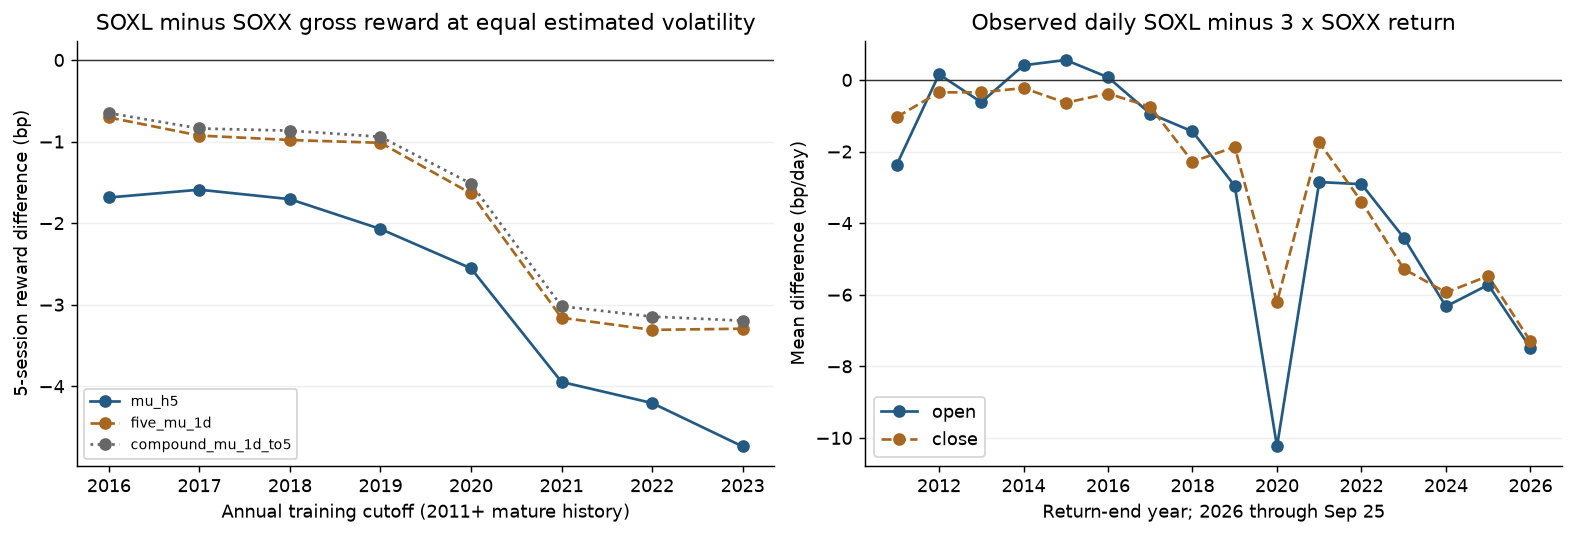

In [4]:
plt.rcParams.update({'figure.dpi':130,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for name,color,style in [('mu_h5','#245A81','-'),('five_mu_1d','#A76721','--'),('compound_mu_1d_to5','#676767',':')]:
    part=scores.loc[scores.risk_definition.eq('last_causal_expanding_open_std') & scores.reward_definition.eq(name)]
    axes[0].plot(part.cutoff_year,part.soxl_minus_soxx_equal_vol_reward*1e4,style,marker='o',color=color,label=name)
axes[0].axhline(0,color='#333333',lw=.8)
axes[0].set(title='SOXL minus SOXX gross reward at equal estimated volatility',xlabel='Annual training cutoff (2011+ mature history)',ylabel='5-session reward difference (bp)')
axes[0].legend(fontsize=8)
for clock,color,style in [('open','#245A81','-'),('close','#A76721','--')]:
    part=paired.loc[paired.clock.eq(clock)]
    axes[1].plot(part.year,part.mean_soxl_minus_3soxx*1e4,style,marker='o',color=color,label=clock)
axes[1].axhline(0,color='#333333',lw=.8)
axes[1].set(title='Observed daily SOXL minus 3 x SOXX return',xlabel='Return-end year; 2026 through Sep 25',ylabel='Mean difference (bp/day)')
axes[1].legend()
for ax in axes: ax.grid(axis='y',alpha=.2)
plt.show()

In [5]:
risk_selected=scores.loc[scores.risk_definition.eq('last_causal_expanding_open_std')]
choices=risk_selected.pivot(index='cutoff_year',columns='reward_definition',values='higher_gross_reward_per_risk')
summary={'same_dates_counts':{str(y):len(d) for y,d in mature_dates.items()},'higher_gross_reward_per_risk_by_cutoff':choices.to_dict(orient='index'),'h5_vs_5mu1_choice_flip_years':choices.index[choices.mu_h5.ne(choices.five_mu_1d)].tolist(),'h5_vs_compound_mu1_choice_flip_years':choices.index[choices.mu_h5.ne(choices.compound_mu_1d_to5)].tolist(),'planning_scope':'Means compare asset holding returns. A daily reoptimized multi-asset portfolio has different compounding, turnover and future holdings; no policy return computed here.'}
payload={'source':source['audit'],'analysis_scope':'read-only planning-moment diagnostic; no model fitting, no new policy or P&L search','cutoff_years':list(range(2016,2024)),'native_arithmetic':'float64 ratios of the same native float32 stored prices','same_h5_mature_dates':mature_dates,'annual_moments':annual.to_dict('records'),'equal_volatility_scores':scores.to_dict('records'),'paired_one_day_by_year_clock':paired.to_dict('records'),'summary':summary,'checks':{'H5_product_identity_max_abs':identity_errors,'daily_label_float32_rounding_max_abs':daily_label_rounding},'limitations':['Previously reviewed historical data; no new out-of-sample evidence.','No financing/index mechanism attribution from arithmetic residuals.','Identical H5-mature dates are used for all moment comparisons; annual price-clock residuals use return-end calendar years.','No costs subtracted from moment means: costs depend on the existing position path, which this diagnostic does not replay.','Equal-volatility scores are algebraic moment normalizations, not portfolio backtests or a source for selected weights.','Published affine basis and 16 secondary Yahoo bars retain parent-source limitations.']}
Path('/tmp/soxl_horizon_moment_diagnostic.json').write_text(json.dumps(payload,indent=2,default=str,allow_nan=False))
display(pd.DataFrame(summary['higher_gross_reward_per_risk_by_cutoff']).T)
print(summary['h5_vs_5mu1_choice_flip_years'])

,compound_mu_1d_to5,five_mu_1d,mu_h5
2016,SOXX,SOXX,SOXX
2017,SOXX,SOXX,SOXX
2018,SOXX,SOXX,SOXX
2019,SOXX,SOXX,SOXX
2020,SOXX,SOXX,SOXX
2021,SOXX,SOXX,SOXX
2022,SOXX,SOXX,SOXX
2023,SOXX,SOXX,SOXX


[]


In [6]:
flips=summary['h5_vs_5mu1_choice_flip_years']
last=annual.loc[annual.cutoff_year.eq(2023)].set_index('instrument')
last_score=scores.loc[scores.cutoff_year.eq(2023) & scores.risk_definition.eq('last_causal_expanding_open_std') & scores.reward_definition.eq('mu_h5')].iloc[0]
text=f"""## 中文结论

完成了同一合格 Qlib 价格源、同一年度 H5 成熟日期上的 μH5 / 5μ1 / (1+μ1)^5−1 比较，并核对 H5 逐日乘积恒等式。年度样本量、成熟截止、两种风险估计口径、OPEN/CLOSE 每日杠杆差均保存在 JSON。

以最后已知 expanding OPEN 风险归一化，μH5 与 5μ1 对 SOXL/SOXX 的 gross reward-per-risk 排序翻转年份：**{flips if flips else '无'}**。全部 8 个 cutoff 的三种矩定义均偏向 SOXX。2023 cutoff 的 SOXL μH5 / 5μ1 分别为 **{last.loc['SOXL','mu_h5']*100:.4f}% / {last.loc['SOXL','five_mu_1d']*100:.4f}%**，SOXX 为 **{last.loc['SOXX','mu_h5']*100:.4f}% / {last.loc['SOXX','five_mu_1d']*100:.4f}%**；同估计波动率下 SOXL 的 H5 gross reward 比 SOXX 少 **{-last_score.soxl_minus_soxx_equal_vol_reward*1e4:.3f} bp**。因此，新来源上的证据不支持“H5资产复利夸大了SOXL吸引力、改用μ1才会偏向SOXX”的解释。

这个结果只检验“更换规划矩是否改变当时资产偏好”的必要环节，不能代替每日资金、成本和风险约束下的完整策略检验。

本次不晋升、不改 Phase 4。风险包括样本重用、重叠 H5 标签、来源复权与二级报价不确定性，以及把资产 H5 回报误当动态组合 H5 期望的语义差异。下一步只能据此另行登记一个定义清楚的机制检验；不能凭本诊断挑选新阈值、仓位或成本参数。

证据：`/tmp/soxl_horizon_moment_diagnostic.json`；父数据 Recorder `bd754e6362b241f194351a1e7aebff6f`。未写入项目仓库或 Recorder，未拟合市场模型，未生成新策略路径。
"""
display(Markdown(text))

## 中文结论

完成了同一合格 Qlib 价格源、同一年度 H5 成熟日期上的 μH5 / 5μ1 / (1+μ1)^5−1 比较，并核对 H5 逐日乘积恒等式。年度样本量、成熟截止、两种风险估计口径、OPEN/CLOSE 每日杠杆差均保存在 JSON。

以最后已知 expanding OPEN 风险归一化，μH5 与 5μ1 对 SOXL/SOXX 的 gross reward-per-risk 排序翻转年份：**无**。全部 8 个 cutoff 的三种矩定义均偏向 SOXX。2023 cutoff 的 SOXL μH5 / 5μ1 分别为 **1.0354% / 1.1060%**，SOXX 为 **0.3908% / 0.3997%**；同估计波动率下 SOXL 的 H5 gross reward 比 SOXX 少 **4.738 bp**。因此，新来源上的证据不支持“H5资产复利夸大了SOXL吸引力、改用μ1才会偏向SOXX”的解释。

这个结果只检验“更换规划矩是否改变当时资产偏好”的必要环节，不能代替每日资金、成本和风险约束下的完整策略检验。

本次不晋升、不改 Phase 4。风险包括样本重用、重叠 H5 标签、来源复权与二级报价不确定性，以及把资产 H5 回报误当动态组合 H5 期望的语义差异。下一步只能据此另行登记一个定义清楚的机制检验；不能凭本诊断挑选新阈值、仓位或成本参数。

证据：`/tmp/soxl_horizon_moment_diagnostic.json`；父数据 Recorder `bd754e6362b241f194351a1e7aebff6f`。未写入项目仓库或 Recorder，未拟合市场模型，未生成新策略路径。
